<b> Load a dataset </b><br>
This downloads the IMDB movie review dataset. After the first download, it loads from cache at ~/.cache/huggingface/datasets/

In [1]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/imdb")
print(dataset)
print(dataset["train"][0])

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and

<b>Step 3: Stream large datasets</b><br>
Some datasets are too large to fit on disk. Streaming loads them row by row without downloading the full thing.<br>
Streaming gives you an IterableDataset. You process rows as they arrive. Memory usage stays constant regardless of dataset size.

In [2]:
dataset = load_dataset("wikimedia/wikipedia", "20231101.en", split="train", streaming=True)

for i, example in enumerate(dataset):
    print(example["title"])
    if i >= 4:
        break

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/41 [00:00<?, ?it/s]

Anarchism
Albedo
A
Alabama
Achilles


<b>Step 4: Dataset formats</b><br>
The datasets library uses Apache Arrow under the hood. You can convert to other formats depending on what your pipeline needs.<br>
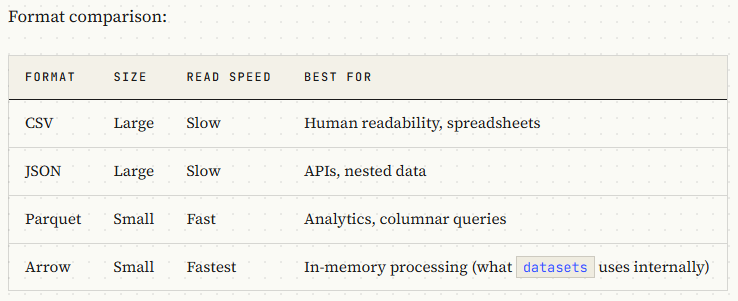<br>
For AI work, Parquet is the best storage format. Arrow is what you work with in memory. CSV and JSON are for interchange.


In [3]:
dataset = load_dataset("stanfordnlp/imdb", split="train")

dataset.to_csv("imdb_train.csv")
dataset.to_json("imdb_train.json")
dataset.to_parquet("imdb_train.parquet")

Creating CSV from Arrow format:   0%|          | 0/25 [00:00<?, ?ba/s]

Creating json from Arrow format:   0%|          | 0/25 [00:00<?, ?ba/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

33432823

<b>Step 5: Data splits</b><br>
Every ML project needs three splits:<br>

Train: The model learns from this (typically 80%)<br>
Validation: You check progress during training (typically 10%)<br>
Test: Final evaluation after training is done (typically 10%)<br>
Some datasets come pre-split. When they don't, split them yourself.<br>
Always set a seed for reproducibility. The same seed produces the same split every time.<br>
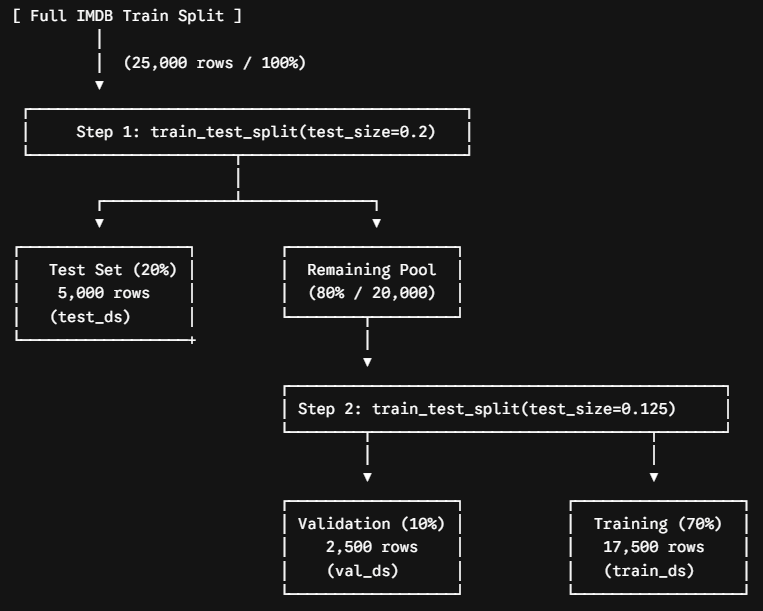

In [ ]:
dataset = load_dataset("stanfordnlp/imdb", split="train") #Downloads and loads the IMDB dataset from Hugging Face

split = dataset.train_test_split(test_size=0.2, seed=42)
# Takes the full dataset and divides it into two parts using a random seed (42) for reproducibility.
# test_size=0.2: Sets aside 20% of the data as the final test set (split["test"])
# The remaining 80% becomes the working training pool (split["train"]).

train_val = split["train"].train_test_split(test_size=0.125, seed=42)
# Takes that remaining 80% pool (split["train"]) and splits it again.
# test_size=0.125: Sets aside 12.5% of the 80% training pool as the validation set (val_ds)
# The remaining 87.5% of the 80% pool becomes the final training set (train_ds)

train_ds = train_val["train"]
val_ds = train_val["test"]
test_ds = split["test"]

print(f"Train: {len(train_ds)}, Val: {len(val_ds)}, Test: {len(test_ds)}")
